# Computer Vision — Section 1 Solutions

<a href="https://colab.research.google.com/github/amr-elgharip2006/cv-section1-opencv-fundamentals/blob/main/CV_Section1_Solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Student:** Amr Ahmed Elgharip — solutions only. Run all cells from the top.

# Solutions — Amr

The solutions below use **OpenCV's sample image `fruits.jpg`** (downloaded from the official OpenCV repository), so they run in Colab **without an upload**.
To use your own image instead, upload it with the cell in section 5 and set `IMAGE_PATH = image_path`.

A second file, `fruits_alpha.png`, is made from the same photo with a transparent background so that `cv2.IMREAD_UNCHANGED` has an alpha channel to show (Exercise 2).

Image: fruits.jpg | shape: (480, 512, 3) | dtype: uint8


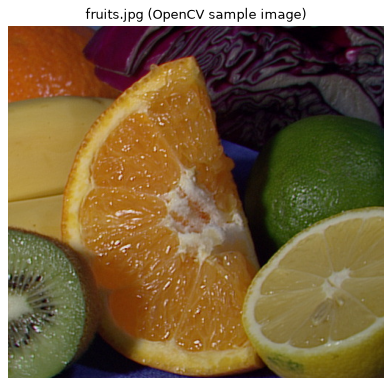

In [1]:
# Setup for the solutions
import os
import urllib.request

import cv2
import numpy as np
import matplotlib.pyplot as plt

SAMPLE_URL = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/fruits.jpg"
IMAGE_PATH = "fruits.jpg"

if not os.path.exists(IMAGE_PATH):
    urllib.request.urlretrieve(SAMPLE_URL, IMAGE_PATH)

original = cv2.imread(IMAGE_PATH, cv2.IMREAD_COLOR)
if original is None:
    raise ValueError("OpenCV could not read " + IMAGE_PATH)

# PNG copy with an alpha channel: opaque inside an ellipse, transparent outside
h, w = original.shape[:2]
alpha = np.zeros((h, w), dtype=np.uint8)
cv2.ellipse(alpha, (w // 2, h // 2), (w // 2 - 20, h // 2 - 20), 0, 0, 360, 255, -1)
bgra = cv2.merge((*cv2.split(original), alpha))
ALPHA_PATH = "fruits_alpha.png"
cv2.imwrite(ALPHA_PATH, bgra)


def show_row(images, titles, cmaps=None, size=4.2):
    """Show several images side by side. BGR images are converted to RGB first."""
    cmaps = cmaps or [None] * len(images)
    plt.figure(figsize=(size * len(images), size), dpi=80)
    for i, (im, title, cmap) in enumerate(zip(images, titles, cmaps)):
        plt.subplot(1, len(images), i + 1)
        if im.ndim == 3 and cmap is None:
            im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
        plt.imshow(im, cmap=cmap, vmin=0 if cmap else None, vmax=255 if cmap else None)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


print("Image:", IMAGE_PATH, "| shape:", original.shape, "| dtype:", original.dtype)
show_row([original], ["fruits.jpg (OpenCV sample image)"], size=5)

### Exercise 1 — Matrix inspection (Solution)

shape : (480, 512)
ndim  : 2
dtype : uint8
min   : 0
max   : 238
mean  : 88.66


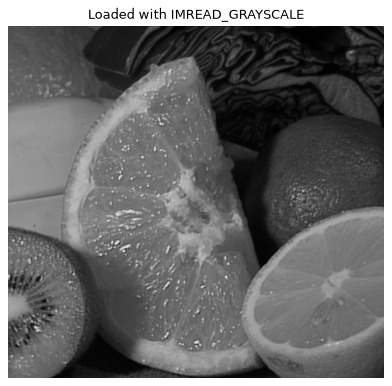

In [2]:
# 1. Load the image in grayscale
gray = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)

# 2. Inspect it
print("shape :", gray.shape)
print("ndim  :", gray.ndim)
print("dtype :", gray.dtype)
print("min   :", gray.min())
print("max   :", gray.max())
print("mean  :", round(float(gray.mean()), 2))

show_row([gray], ["Loaded with IMREAD_GRAYSCALE"], cmaps=["gray"], size=5)

**3. Why does the shape have two values instead of three?**
A grayscale image stores **one intensity value per pixel**, so a 2-D matrix `(height, width)` is enough.
A color image needs **three values per pixel** (B, G, R), so it needs a third axis: `(height, width, 3)`.
OpenCV does not keep a channel axis of size 1 for grayscale images, which is why `gray.ndim` is `2`.

### Exercise 2 — `imread` flags (Solution)

In [3]:
flags = {
    "IMREAD_COLOR": cv2.IMREAD_COLOR,
    "IMREAD_GRAYSCALE": cv2.IMREAD_GRAYSCALE,
    "IMREAD_UNCHANGED": cv2.IMREAD_UNCHANGED,
}

print(f"{'file':<18}{'flag':<20}{'shape':<18}dtype")
print("-" * 62)
for path in [IMAGE_PATH, ALPHA_PATH]:
    for name, flag in flags.items():
        arr = cv2.imread(path, flag)
        print(f"{path:<18}{name:<20}{str(arr.shape):<18}{arr.dtype}")
    print()

file              flag                shape             dtype
--------------------------------------------------------------
fruits.jpg        IMREAD_COLOR        (480, 512, 3)     uint8
fruits.jpg        IMREAD_GRAYSCALE    (480, 512)        uint8
fruits.jpg        IMREAD_UNCHANGED    (480, 512, 3)     uint8

fruits_alpha.png  IMREAD_COLOR        (480, 512, 3)     uint8
fruits_alpha.png  IMREAD_GRAYSCALE    (480, 512)        uint8
fruits_alpha.png  IMREAD_UNCHANGED    (480, 512, 4)     uint8



| Flag | `fruits.jpg` (no alpha) | `fruits_alpha.png` (with alpha) | What it does |
|---|---|---|---|
| `IMREAD_COLOR` | `(480, 512, 3)` | `(480, 512, 3)` | Always 3-channel BGR; alpha is **dropped** |
| `IMREAD_GRAYSCALE` | `(480, 512)` | `(480, 512)` | One intensity channel |
| `IMREAD_UNCHANGED` | `(480, 512, 3)` | `(480, 512, 4)` | Loads the file **as stored**, so the PNG keeps its alpha channel (BGRA) |

All results are `uint8` because both files are 8-bit images. `IMREAD_UNCHANGED` only differs from `IMREAD_COLOR` when the file has something extra: an alpha channel or a higher bit depth (e.g. 16-bit PNG).

### Exercise 3 — RGB / BGR (Solution)

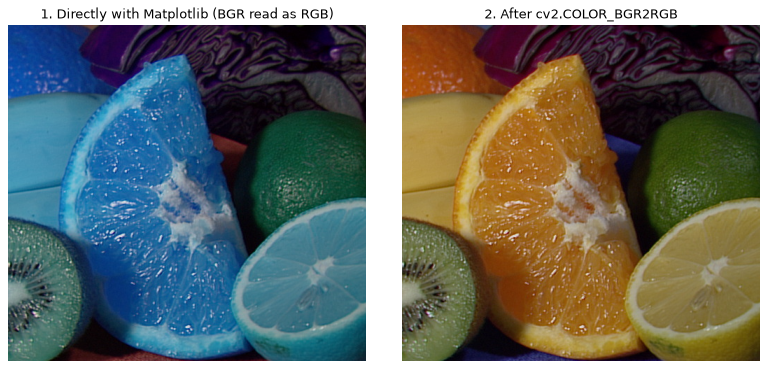

Orange pixel as stored by OpenCV (B, G, R): [ 93 146 196]
Same pixel after BGR2RGB      (R, G, B): [196 146  93]


In [4]:
img_bgr = cv2.imread(IMAGE_PATH, cv2.IMREAD_COLOR)

plt.figure(figsize=(10, 4.6), dpi=80)
plt.subplot(1, 2, 1)
plt.imshow(img_bgr)                                   # 1. directly (wrong)
plt.title("1. Directly with Matplotlib (BGR read as RGB)")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))  # 2. converted (correct)
plt.title("2. After cv2.COLOR_BGR2RGB")
plt.axis("off")
plt.tight_layout()
plt.show()

y, x = 240, 200   # a pixel inside the orange
print("Orange pixel as stored by OpenCV (B, G, R):", img_bgr[y, x])
print("Same pixel after BGR2RGB      (R, G, B):", cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)[y, x])

**Why the colors differ:** OpenCV stores the channels in the order **B, G, R**, but Matplotlib assumes **R, G, B**.
Without conversion the first and third channels are swapped: the **red** values are drawn as **blue** and the blue values as red, while green stays the same.
That is why the orange and the lemon turn **blue / cyan** in image 1, while the bluish cloth at the bottom turns **red**. `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` swaps them back, so image 2 shows the real colors.

### Exercise 4 — Channels (Solution)

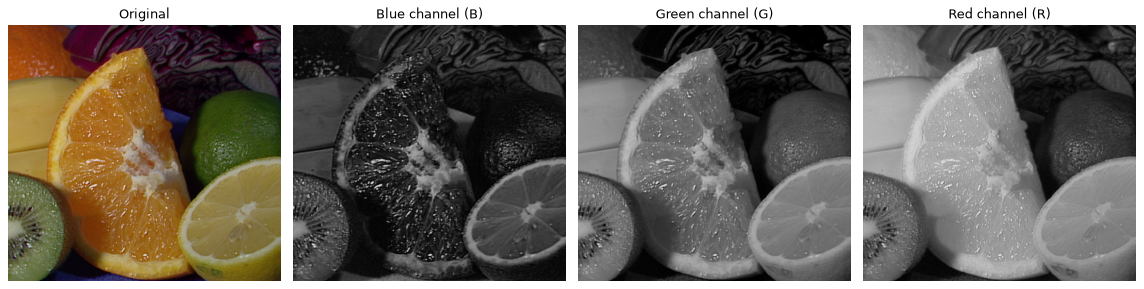

B: mean =   46.2   min =   0   max = 245
G: mean =   85.6   min =   0   max = 238
R: mean =  110.8   min =   0   max = 252


In [5]:
b, g, r = cv2.split(img_bgr)

show_row([img_bgr, b, g, r],
         ["Original", "Blue channel (B)", "Green channel (G)", "Red channel (R)"],
         cmaps=[None, "gray", "gray", "gray"], size=3.6)

for name, ch in [("B", b), ("G", g), ("R", r)]:
    print(f"{name}: mean = {ch.mean():6.1f}   min = {ch.min():3d}   max = {ch.max():3d}")

Each channel is shown as a grayscale image: **bright = that color component is strong at this pixel**, dark = it is weak.

- **Red channel (brightest overall, mean ≈ 111):** the orange slice and the orange in the top-left are the brightest areas, and the lemon and banana are bright too, because orange and yellow contain a lot of red. The green lime is dark.
- **Green channel (mean ≈ 86):** the lemon and the banana are bright (yellow = red + green), the orange is only medium (orange has less green than yellow), the dark-green lime is medium, and the purple cabbage is dark.
- **Blue channel (darkest, mean ≈ 46):** the orange flesh is dark because orange has almost no blue, so its white pith and shiny highlights stand out. The pale lemon is medium (pale yellow is close to white), and the lime is dark.
- White areas (the pith and the highlights) are bright in **all three** channels.

So a region that is bright in only one channel has a pure color, a region that is bright in all three channels is white or light gray, and a region that is dark in all three is black.

### Exercise 5 — `uint8` (Solution)

In [6]:
arr = np.array([0, 100, 200, 255], dtype=np.uint8)

# Direct uint8 addition -> wrap-around (modulo 256)
wrapped = arr + np.uint8(20)
print("original          :", arr)
print("uint8 + 20        :", wrapped, "  <- 255 + 20 = 275, and 275 - 256 = 19")

# Safe version: compute in int16, clip to 0..255, convert back
safe = np.clip(arr.astype(np.int16) + 20, 0, 255).astype(np.uint8)
print("int16 + 20, clip  :", safe, " <- 255 + 20 is clipped to 255")

# Bonus: OpenCV arithmetic saturates automatically
# (reshape to a 1x4 image: a plain 4-element array would be read by OpenCV as a Scalar)
row = arr.reshape(1, -1)
saturated = cv2.add(row, np.full_like(row, 20)).ravel()
print("cv2.add (saturate):", saturated)

original          : [  0 100 200 255]
uint8 + 20        : [ 20 120 220  19]   <- 255 + 20 = 275, and 275 - 256 = 19
int16 + 20, clip  : [ 20 120 220 255]  <- 255 + 20 is clipped to 255
cv2.add (saturate): [ 20 120 220 255]


`uint8` can only hold 0–255. NumPy does `uint8` arithmetic **modulo 256**, so `255 + 20` becomes `19` (a white pixel would suddenly turn almost black).
The safe way is to compute in a wider type (`int16` can hold −32768…32767), **clip** the result to 0–255, then convert back to `uint8`.
OpenCV's own functions (`cv2.add`, `cv2.subtract`) use **saturation** instead, so they give the same safe result directly.

### Exercise 6 — Coordinates (Solution)

top-left      (x=  0, y=  0) -> img[0, 0] = BGR [ 13  62 130]
center        (x=256, y=240) -> img[240, 256] = BGR [ 43  84 129]
bottom-right  (x=511, y=479) -> img[479, 511] = BGR [17 40 55]

Before: [ 43  84 129]
After : [  0   0 255]


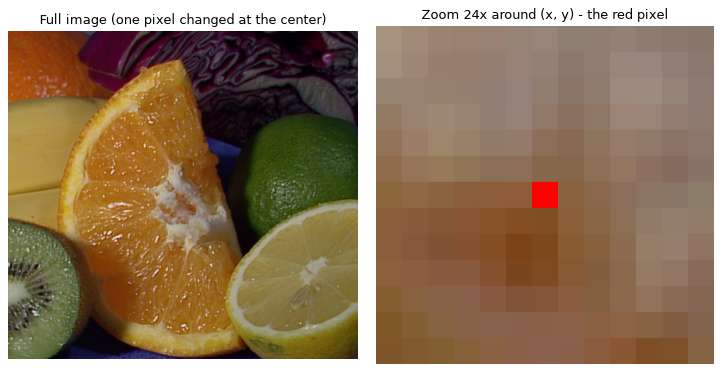

In [7]:
img = img_bgr.copy()
h, w = img.shape[:2]

points = {
    "top-left": (0, 0),
    "center": (w // 2, h // 2),
    "bottom-right": (w - 1, h - 1),
}
for name, (x, y) in points.items():
    print(f"{name:<13} (x={x:3d}, y={y:3d}) -> img[{y}, {x}] = BGR {img[y, x]}")

# Change ONE pixel to pure red (BGR = 0, 0, 255)
x, y = w // 2, h // 2
print("\nBefore:", img[y, x])
img[y, x] = (0, 0, 255)
print("After :", img[y, x])

# One pixel is too small to see in the full image, so also show a zoomed crop around it
zoom = cv2.resize(img[y - 6:y + 7, x - 6:x + 7], None, fx=24, fy=24,
                  interpolation=cv2.INTER_NEAREST)
show_row([img, zoom], ["Full image (one pixel changed at the center)",
                       "Zoom 24x around (x, y) - the red pixel"], size=4.6)

Points are written as **(x, y)** but NumPy indexes **`img[y, x]`** (row first, then column). The bottom-right pixel is `(w − 1, h − 1)` because indexing starts at 0.

### Exercise 7 — Reconstruct an image (Solution)

Same order (b, g, r) -> np.array_equal: True
Wrong order (r, g, b) -> np.array_equal: False


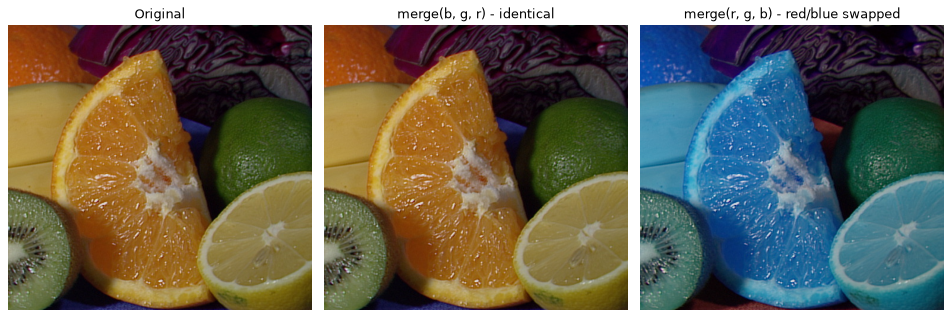

In [8]:
original = cv2.imread(IMAGE_PATH, cv2.IMREAD_COLOR)

b, g, r = cv2.split(original)
reconstructed = cv2.merge((b, g, r))
print("Same order (b, g, r) -> np.array_equal:", np.array_equal(original, reconstructed))

# What happens with the wrong order?
wrong = cv2.merge((r, g, b))
print("Wrong order (r, g, b) -> np.array_equal:", np.array_equal(original, wrong))

show_row([original, reconstructed, wrong],
         ["Original", "merge(b, g, r) - identical", "merge(r, g, b) - red/blue swapped"], size=4)

### Slide 14 exercise — Modify a region (Solution)

*"Choose a small region and set it to a solid color. Then print the pixel before and after the modification."*

Before: [129 152 154]
After : [255   0   0]


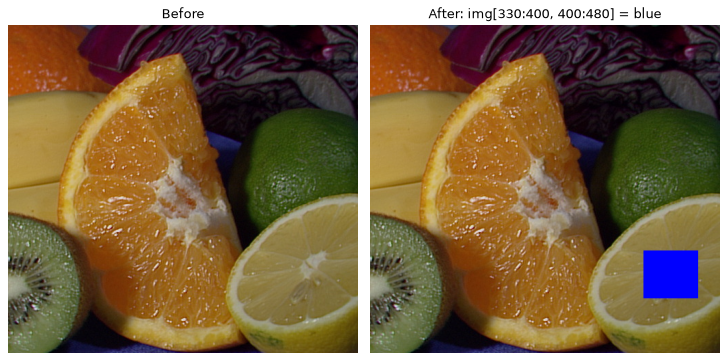

In [9]:
img = img_bgr.copy()

y1, y2, x1, x2 = 330, 400, 400, 480        # a small region on the lemon
probe = (360, 440)                          # a pixel inside that region (row, col)

print("Before:", img[probe])
img[y1:y2, x1:x2] = (255, 0, 0)            # BGR -> solid blue
print("After :", img[probe])

show_row([img_bgr, img], ["Before", f"After: img[{y1}:{y2}, {x1}:{x2}] = blue"], size=4.6)

Slicing uses **`[y1:y2, x1:x2]`** (rows first). Assigning one BGR tuple to the slice fills every pixel in the region with that color.

### Starter template — completed

In [10]:
# TODO 1: Load an image in grayscale.
gray = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)

# TODO 2: Inspect its shape and dtype.
print("Grayscale:", gray.shape, gray.dtype)

# TODO 3: Split the color image.
color = cv2.imread(IMAGE_PATH, cv2.IMREAD_COLOR)
b, g, r = cv2.split(color)
print("Channels :", b.shape, g.shape, r.shape)

# TODO 4: Merge the channels.
merged = cv2.merge((b, g, r))

# TODO 5: Verify reconstruction.
print("Reconstruction equal:", np.array_equal(color, merged))

Grayscale: (480, 512) uint8
Channels : (480, 512) (480, 512) (480, 512)
Reconstruction equal: True
